# Training Model Jenis Tanaman, transfer learning MobileNetV2
Kelas: jagung, jambu_biji, kentang, lainnya, mangga, monstera, padi, paprika_cabai, tomat (9 kelas).
Aturan penerimaan (dikunci sebelum training): macro F1 val ≥ 0,793 dan test ≥ 0,784.
Satu run. Test dijalankan sekali, hanya jika val lolos.

### Bagian 1 — Setup Colab

In [1]:
import tensorflow as tf

# 1. Mencetak versi TensorFlow
print(f"Versi TensorFlow: {tf.__version__}")

# 2. Menghentikan notebook dengan pesan jelas kalau GPU tidak ada
gpus = tf.config.list_physical_devices("GPU")
assert len(gpus) > 0, "GPU tidak ditemukan! Harap ganti runtime ke T4 GPU di menu Runtime > Change runtime type."

# 3. Mengatur seed tetap SEED = 42 agar hasilnya bisa direproduksi
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print(f"Random seed diatur ke {SEED}")

Versi TensorFlow: 2.21.0
Random seed diatur ke 42


### Bagian 2 — Ambil data dan buang augmentasi J4

In [2]:
import zipfile
import shutil
from pathlib import Path
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# Jalur file zip di Drive (sesuaikan nama foldernya jika berada di dalam folder tertentu)
zip_path = Path('/content/drive/MyDrive/jenis_bundle.zip')
extract_path = Path('/content/data_jenis')

# Ekstrak file zip jika belum diekstrak
if not extract_path.exists():
    print("Mengekstrak jenis_bundle.zip...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Ekstraksi selesai.")
else:
    print("Data sudah diekstrak sebelumnya.")

DATA = Path("/content/data_jenis/data/jenis")

Mounted at /content/drive
Mengekstrak jenis_bundle.zip...
Ekstraksi selesai.


In [3]:
# 2. Menghapus semua bgaug__*.jpg di folder train
bgaug_files = list(DATA.glob("train/*/bgaug__*.jpg"))
num_deleted = len(bgaug_files)

for p in bgaug_files:
    p.unlink()

print(f"Jumlah file bgaug__*.jpg yang dihapus: {num_deleted}")
assert not list(DATA.glob("train/*/bgaug__*.jpg")), "Masih ada file bgaug!"


Jumlah file bgaug__*.jpg yang dihapus: 2871


In [4]:
# 3. Mendefinisikan CLASS_NAMES (9 kelas alfabetis)
CLASS_NAMES = sorted([d.name for d in (DATA / "train").iterdir() if d.is_dir()])
print(f"Class Names ({len(CLASS_NAMES)} kelas): {CLASS_NAMES}")
assert CLASS_NAMES == ["jagung", "jambu_biji", "kentang", "lainnya", "mangga",
                       "monstera", "padi", "paprika_cabai", "tomat"], CLASS_NAMES


Class Names (9 kelas): ['jagung', 'jambu_biji', 'kentang', 'lainnya', 'mangga', 'monstera', 'padi', 'paprika_cabai', 'tomat']


In [5]:
# 4. Mencocokkan dengan split.csv yang difilter
df = pd.read_csv(DATA / "split.csv")
df_filtered = df[df.source != "bgaug"].copy()

# Hitung jumlah file fisik di direktori
split_counts_actual = {}
for split in ["train", "val", "test"]:
    split_counts_actual[split] = len(list(DATA.glob(f"{split}/*/*.jpg")))

print("Jumlah file fisik per split:", split_counts_actual)

# Verifikasi dengan asersi sesuai spesifikasi
assert split_counts_actual["train"] == 8929, f"Train count {split_counts_actual['train']} != 8929"
assert split_counts_actual["val"] == 1893, f"Val count {split_counts_actual['val']} != 1893"
assert split_counts_actual["test"] == 1924, f"Test count {split_counts_actual['test']} != 1924"
assert sum(split_counts_actual.values()) == 12746, "Total gambar fisik tidak sama dengan 12746"

# Verifikasi dengan dataframe yang difilter
for split in ["train", "val", "test"]:
    df_split_count = len(df_filtered[df_filtered.split == split])
    assert split_counts_actual[split] == df_split_count, f"Ketidakcocokan pada split {split} antara fisik dan CSV!"

print("Semua asersi lolos! Struktur dataset valid.")

Jumlah file fisik per split: {'train': 8929, 'val': 1893, 'test': 1924}
Semua asersi lolos! Struktur dataset valid.


In [6]:
# 5. Menampilkan jumlah per kelas di split train untuk laporan
train_class_counts = {}
for c in CLASS_NAMES:
    train_class_counts[c] = len(list((DATA / "train" / c).glob("*.jpg")))

df_report = pd.DataFrame(list(train_class_counts.items()), columns=["Kelas", "Jumlah Train"])
display(df_report)

,Kelas,Jumlah Train
0,jagung,550
1,jambu_biji,496
2,kentang,1400
3,lainnya,1400
4,mangga,519
5,monstera,1400
6,padi,364
7,paprika_cabai,1400
8,tomat,1400


### Bagian 3 & 4 — Memuat data, cache, augmentasi

In [7]:
IMG_SIZE = 128
BATCH = 32

print("Memuat dataset dari folder...")
# Train di-load tanpa batch (batch_size=None) dan di-shuffle
train_raw = tf.keras.utils.image_dataset_from_directory(
    DATA / "train",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=None,
    shuffle=True,
    seed=SEED
)

# Val dan test di-load langsung dengan BATCH dan TANPA shuffle
val_raw = tf.keras.utils.image_dataset_from_directory(
    DATA / "val",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH,
    shuffle=False,
    seed=SEED
)
val_paths = val_raw.file_paths

test_raw = tf.keras.utils.image_dataset_from_directory(
    DATA / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH,
    shuffle=False,
    seed=SEED
)
test_paths = test_raw.file_paths

Memuat dataset dari folder...
Found 8929 files belonging to 9 classes.
Found 1893 files belonging to 9 classes.
Found 1924 files belonging to 9 classes.


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

# Pipeline Augmentasi (sama dengan referensi J3)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.1, seed=SEED),
    tf.keras.layers.RandomZoom(0.1, seed=SEED),
    tf.keras.layers.RandomContrast(0.1, seed=SEED),
    tf.keras.layers.Rescaling(1./255)
])

# Helper functions
def cast_to_uint8(image, label):
    return tf.cast(image, tf.uint8), label

def rescale_only(image, label):
    return tf.cast(image, tf.float32) / 255.0, label

# Pipeline Train: cast -> cache -> shuffle -> batch -> augmentasi+rescale -> prefetch
train_ds = (
    train_raw
    .map(cast_to_uint8, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(9000, seed=SEED)
    .batch(BATCH)
    .map(lambda img, label: (data_augmentation(tf.cast(img, tf.float32), training=True), label), num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Pipeline Val & Test: cast -> cache -> rescale -> prefetch
val_ds = (
    val_raw
    .map(cast_to_uint8, num_parallel_calls=AUTOTUNE)
    .cache()
    .map(rescale_only, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(cast_to_uint8, num_parallel_calls=AUTOTUNE)
    .cache()
    .map(rescale_only, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)


In [9]:
print(f"Panjang val_paths: {len(val_paths)}")

# Cek min dan max pada satu batch train untuk memastikan rescaling ke 0-1 berhasil
for images, labels in train_ds.take(1):
    print(f"Bentuk gambar: {images.shape}")
    print(f"Nilai min pixel: {tf.reduce_min(images).numpy():.4f}")
    print(f"Nilai max pixel: {tf.reduce_max(images).numpy():.4f}")

Panjang val_paths: 1893
Bentuk gambar: (32, 128, 128, 3)
Nilai min pixel: 0.0000
Nilai max pixel: 1.0000


### Bagian 5 — Membangun model dengan transfer learning (MobileNetV2)

In [10]:
def build_model(num_classes=9):
    # Mengambil base model dari MobileNetV2 dengan bobot ImageNet
    base = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    # Membekukan base model agar bobot tidak berubah pada fase awal training
    base.trainable = False

    # Arsitektur Kepala (Head)
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    # Mengubah rentang 0-1 menjadi -1 sampai 1 yang dibutuhkan oleh MobileNetV2
    x = tf.keras.layers.Rescaling(2.0, offset=-1.0)(inputs)
    # Melewatkan ke base model. training=False menjaga BatchNorm tetap memakai statistik ImageNet
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3, seed=SEED)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name="JenisTanaman_MobileNetV2")
    return model, base

model, base = build_model()
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "JenisTanaman_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
import numpy as np

# Menghitung parameter
total_params = model.count_params()
# Cara aman Keras 3
trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))

print(f"Total parameter: {total_params:,}")
print(f"Trainable parameter: {trainable_params:,}")

# Memvalidasi model dengan input dummy
dummy_input = tf.zeros((2, IMG_SIZE, IMG_SIZE, 3))
dummy_output = model(dummy_input)
row_sums = np.sum(dummy_output.numpy(), axis=1)

print(f"\nBentuk output dummy: {dummy_output.shape}")
print(f"Jumlah probabilitas per baris: {row_sums}")

# Asersi pengaman
assert trainable_params == 11529, f"Expected 11529 trainable params, got {trainable_params}"
assert dummy_output.shape == (2, 9), f"Expected shape (2, 9), got {dummy_output.shape}"
assert np.allclose(row_sums, 1.0), "Total probabilitas per baris tidak sama dengan 1!"

print("\nSemua asersi model lolos!")

Total parameter: 2,269,513
Trainable parameter: 11,529

Bentuk output dummy: (2, 9)
Jumlah probabilitas per baris: [0.9999999 0.9999999]

Semua asersi model lolos!


### Bagian 6 — Training 2 Fase

In [12]:
# Sel A - Fase 1: Melatih Kepala
OUT = Path("/content/drive/MyDrive/training_jenis")
OUT.mkdir(parents=True, exist_ok=True)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

callbacks_p1 = [
    tf.keras.callbacks.ModelCheckpoint(filepath=OUT/"best.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.CSVLogger(OUT/"history.csv")
]

print("Memulai Fase 1...")
h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_p1
)

Memulai Fase 1...
Epoch 1/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 94s 250ms/step - accuracy: 0.5838 - loss: 1.2395 - val_accuracy: 0.7052 - val_loss: 0.8568 - learning_rate: 0.0010
Epoch 2/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 90s 134ms/step - accuracy: 0.6784 - loss: 0.9138 - val_accuracy: 0.7290 - val_loss: 0.7679 - learning_rate: 0.0010
Epoch 3/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 35s 126ms/step - accuracy: 0.7018 - loss: 0.8601 - val_accuracy: 0.7327 - val_loss: 0.7653 - learning_rate: 0.0010
Epoch 4/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 38s 133ms/step - accuracy: 0.7156 - loss: 0.8076 - val_accuracy: 0.7501 - val_loss: 0.7229 - learning_rate: 0.0010
Epoch 5/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 36s 128ms/step - accuracy: 0.7230 - loss: 0.8023 - val_accuracy: 0.7570 - val_loss: 0.7060 - learning_rate: 0.0010
Epoch 6/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 36s 127ms/step - accuracy: 0.7336 - loss: 0.7692 - val_accuracy: 0.7570 - val_loss: 0.7130 - learning_rate: 0.0010
Epoch 7/15
280/280 ━━━━━━━━━━━━━━━━━━━━ 36s 126ms/st

In [13]:
# Sel B - Fase 2: Fine-Tuning
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

# Membekukan BatchNormalization
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

trainable_base_layers = sum([1 for layer in base.layers if layer.trainable])
print(f"Jumlah lapisan base yang trainable: {trainable_base_layers}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

best_val_loss_p1 = min(h1.history["val_loss"])

callbacks_p2 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=OUT/"best.keras",
        monitor="val_loss",
        save_best_only=True,
        initial_value_threshold=best_val_loss_p1
    ),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
    tf.keras.callbacks.CSVLogger(OUT/"history.csv", append=True)
]

done = len(h1.history["loss"])
print(f"\nMemulai Fase 2 dari epoch {done}...")

h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=done,
    epochs=done + 20,
    callbacks=callbacks_p2
)

Jumlah lapisan base yang trainable: 26

Memulai Fase 2 dari epoch 15...
Epoch 16/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 68s 187ms/step - accuracy: 0.7497 - loss: 0.6868 - val_accuracy: 0.7538 - val_loss: 0.6941 - learning_rate: 1.0000e-05
Epoch 17/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - accuracy: 0.7637 - loss: 0.6606 - val_accuracy: 0.7728 - val_loss: 0.6703 - learning_rate: 1.0000e-05
Epoch 18/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 37s 132ms/step - accuracy: 0.7765 - loss: 0.6143 - val_accuracy: 0.7755 - val_loss: 0.6523 - learning_rate: 1.0000e-05
Epoch 19/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 42s 138ms/step - accuracy: 0.7908 - loss: 0.5911 - val_accuracy: 0.7850 - val_loss: 0.6294 - learning_rate: 1.0000e-05
Epoch 20/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 35s 126ms/step - accuracy: 0.7911 - loss: 0.5825 - val_accuracy: 0.7824 - val_loss: 0.6337 - learning_rate: 1.0000e-05
Epoch 21/35
280/280 ━━━━━━━━━━━━━━━━━━━━ 37s 131ms/step - accuracy: 0.7964 - loss: 0.5611 - val_accuracy: 0.7776 - val_loss: 0.6

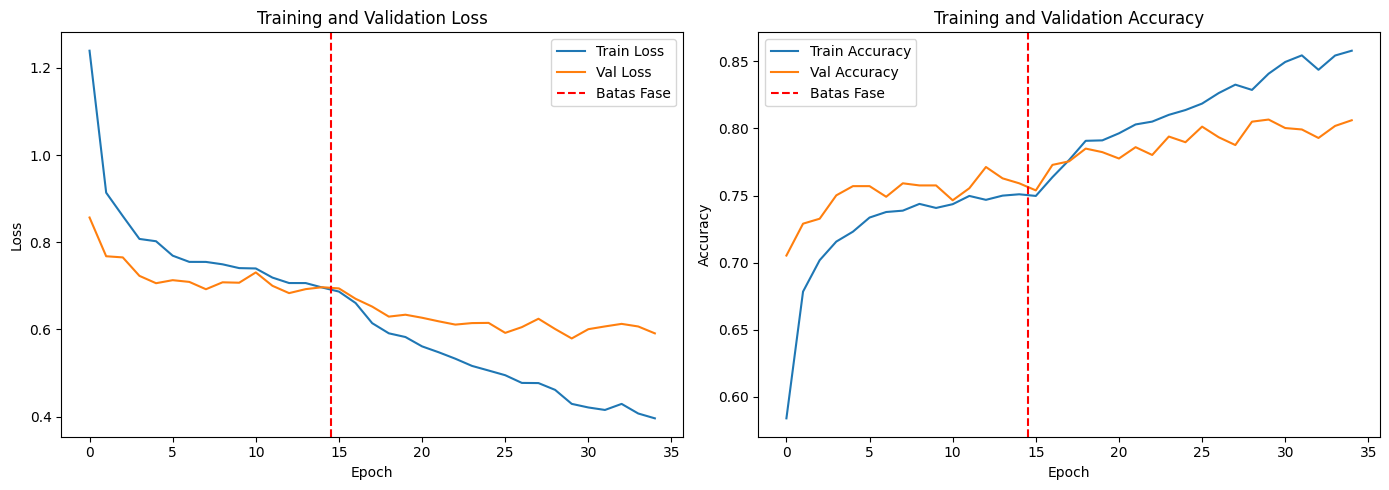

In [14]:
# Sel C - Grafik Loss dan Accuracy
import matplotlib.pyplot as plt

df_hist = pd.read_csv(OUT/"history.csv")
done = len(h1.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Loss
axes[0].plot(df_hist["epoch"], df_hist["loss"], label="Train Loss")
axes[0].plot(df_hist["epoch"], df_hist["val_loss"], label="Val Loss")
axes[0].axvline(done - 0.5, color='r', linestyle='--', label="Batas Fase")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Grafik Accuracy
axes[1].plot(df_hist["epoch"], df_hist["accuracy"], label="Train Accuracy")
axes[1].plot(df_hist["epoch"], df_hist["val_accuracy"], label="Val Accuracy")
axes[1].axvline(done - 0.5, color='r', linestyle='--', label="Batas Fase")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUT/"history.png")
plt.show()

### Bagian 7 — Evaluasi di data validasi

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score
import numpy as np
import matplotlib.pyplot as plt

print("Memuat model terbaik dari checkpoint...")
model = tf.keras.models.load_model(OUT / "best.keras")

print("Memproses prediksi pada data validasi...")
probs = model.predict(val_ds)
y_pred = np.argmax(probs, axis=1)

# Ekstrak label asli
y_true = []
for images, labels in val_ds:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# Ekstrak sumber dataset dari nama file
# Format penamaan: inat__...jpg, leaves__...jpg, dll.
sources_val = [Path(p).name.split("__")[0] for p in val_paths]

# Memastikan jumlahnya pas 1893
assert len(y_pred) == 1893, f"Prediksi: {len(y_pred)} != 1893"
assert len(y_true) == 1893, f"Label Asli: {len(y_true)} != 1893"
assert len(sources_val) == 1893, f"Sumber: {len(sources_val)} != 1893"

# 1. Classification Report
print("\nClassification Report (Validation):")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

Memuat model terbaik dari checkpoint...
Memproses prediksi pada data validasi...
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step

Classification Report (Validation):
               precision    recall  f1-score   support

       jagung     0.8454    0.7961    0.8200       103
   jambu_biji     0.8990    0.8165    0.8558       109
      kentang     0.8063    0.8467    0.8260       300
      lainnya     0.5913    0.7667    0.6676       300
       mangga     0.8889    0.7767    0.8290       103
     monstera     0.8381    0.8800    0.8585       300
         padi     0.9275    0.8205    0.8707        78
paprika_cabai     0.9100    0.8767    0.8930       300
        tomat     0.8739    0.6700    0.7585       300

     accuracy                         0.8067      1893
    macro avg     0.8423    0.8055    0.8199      1893
 weighted avg     0.8214    0.8067    0.8094      1893



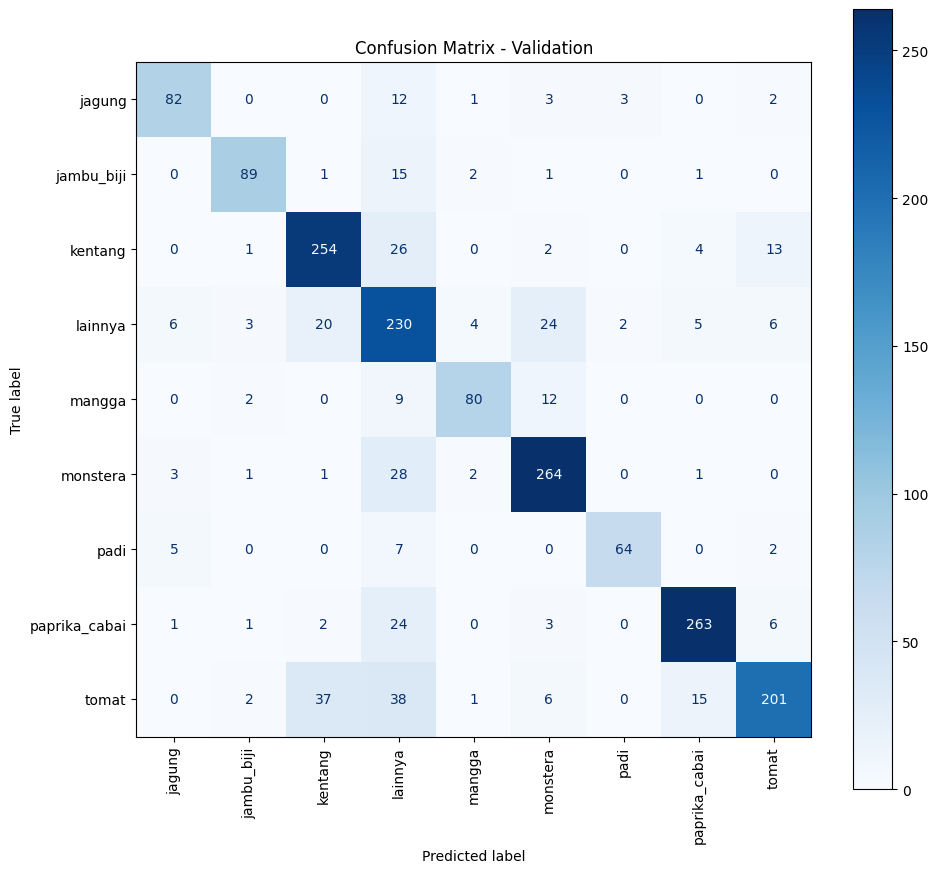


Akurasi per Sumber (Validation):
inat           : 0.7981 (431 citra)
inatj          : 0.6703 (549 citra)
leaves         : 1.0000 (132 citra)
plantdoc       : 0.6167 (227 citra)
plantvillage   : 0.9869 (536 citra)
rice           : 0.7778 (18 citra)

Macro F1 Validasi: 0.8199
STATUS VAL: LOLOS (≥ 0.793)


In [16]:
# 2. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(10, 9))
disp.plot(cmap="Blues", ax=ax, xticks_rotation=90)
plt.title("Confusion Matrix - Validation")
plt.tight_layout()
plt.savefig(OUT / "cm_val.png")
plt.show()

# 3. Akurasi per Sumber
print("\nAkurasi per Sumber (Validation):")
df_val = pd.DataFrame({"y_true": y_true, "y_pred": y_pred, "source": sources_val})
for src, group in df_val.groupby("source"):
    acc = accuracy_score(group["y_true"], group["y_pred"])
    print(f"{src:15s}: {acc:.4f} ({len(group)} citra)")

# 4. Evaluasi Lolos / Gagal
macro_f1_val = f1_score(y_true, y_pred, average="macro")
print(f"\nMacro F1 Validasi: {macro_f1_val:.4f}")
if macro_f1_val >= 0.793:
    print("STATUS VAL: LOLOS (≥ 0.793)")
else:
    print("STATUS VAL: GAGAL (< 0.793)")

### Bagian 8 & 9 — Evaluasi Test, Ekspor TFLite, & Ambang Batas

Memproses prediksi pada data test...
61/61 ━━━━━━━━━━━━━━━━━━━━ 20s 335ms/step

Classification Report (Test):
               precision    recall  f1-score   support

       jagung     0.8649    0.8000    0.8312       120
   jambu_biji     0.8350    0.7611    0.7963       113
      kentang     0.8400    0.8400    0.8400       300
      lainnya     0.5558    0.7300    0.6311       300
       mangga     0.8958    0.7611    0.8230       113
     monstera     0.8030    0.8833    0.8413       300
         padi     0.9118    0.7949    0.8493        78
paprika_cabai     0.8983    0.8833    0.8908       300
        tomat     0.8899    0.6733    0.7666       300

     accuracy                         0.7968      1924
    macro avg     0.8327    0.7919    0.8077      1924
 weighted avg     0.8142    0.7968    0.8004      1924



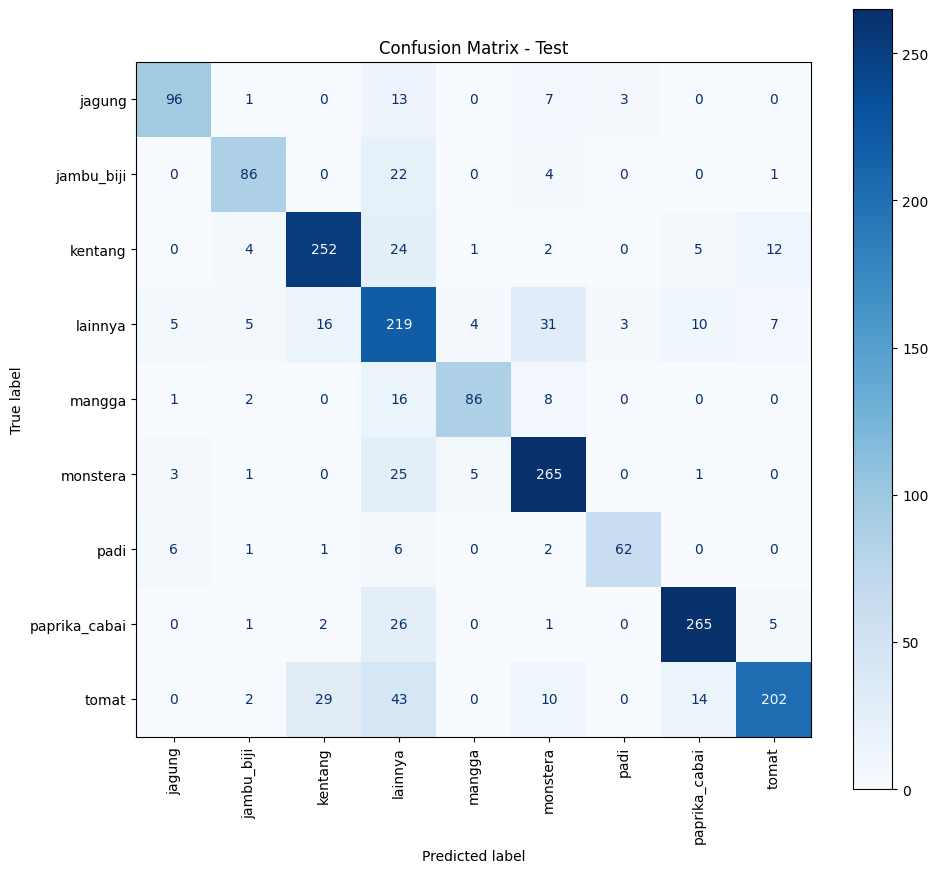


Akurasi per Sumber (Test):
inat           : 0.7788 (443 citra)
inatj          : 0.6413 (552 citra)
leaves         : 0.9847 (131 citra)
plantdoc       : 0.6496 (234 citra)
plantvillage   : 0.9817 (546 citra)
rice           : 0.9444 (18 citra)

Macro F1 Test: 0.8077
STATUS TEST: LOLOS (≥ 0.784)


In [17]:
# Bagian 8 - Evaluasi Test
print("Memproses prediksi pada data test...")
probs_test = model.predict(test_ds)
y_pred_test = np.argmax(probs_test, axis=1)

y_true_test = []
for images, labels in test_ds:
    y_true_test.extend(labels.numpy())
y_true_test = np.array(y_true_test)

sources_test = [Path(p).name.split("__")[0] for p in test_paths]

# Asersi jumlah 1924
assert len(y_pred_test) == 1924
assert len(y_true_test) == 1924
assert len(sources_test) == 1924

print("\nClassification Report (Test):")
report_str = classification_report(y_true_test, y_pred_test, target_names=CLASS_NAMES, digits=4)
print(report_str)

# Simpan report ke file txt
with open(OUT / "report_test.txt", "w") as f:
    f.write(report_str)

# Confusion Matrix Test
cm_test = confusion_matrix(y_true_test, y_pred_test)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 9))
disp_test.plot(cmap="Blues", ax=ax, xticks_rotation=90)
plt.title("Confusion Matrix - Test")
plt.tight_layout()
plt.savefig(OUT / "cm_test.png")
plt.show()

print("\nAkurasi per Sumber (Test):")
df_test = pd.DataFrame({"y_true": y_true_test, "y_pred": y_pred_test, "source": sources_test})
for src, group in df_test.groupby("source"):
    acc = accuracy_score(group["y_true"], group["y_pred"])
    print(f"{src:15s}: {acc:.4f} ({len(group)} citra)")

macro_f1_test = f1_score(y_true_test, y_pred_test, average="macro")
print(f"\nMacro F1 Test: {macro_f1_test:.4f}")
if macro_f1_test >= 0.784:
    print("STATUS TEST: LOLOS (≥ 0.784)")
else:
    print("STATUS TEST: GAGAL (< 0.784)")


In [18]:
import json
import os

# Bagian 9 - Ekspor TFLite dan Labels
print("Mengekspor model ke format TFLite...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

tflite_path = OUT / "jenis.tflite"
with open(tflite_path, "wb") as f:
    f.write(tflite_model)

size_kb = os.path.getsize(tflite_path) / 1024
print(f"TFLite disimpan di: {tflite_path}")
print(f"Ukuran file TFLite: {size_kb:.2f} KB (Target sekitar ~8700 KB)")

# Ekspor Label
labels_path = OUT / "jenis_labels.json"
with open(labels_path, "w") as f:
    json.dump(CLASS_NAMES, f)
print(f"Daftar label disimpan di: {labels_path}")

# Pengecekan TFLite vs Keras
print("\nMemeriksa perbedaan prediksi Keras vs TFLite...")
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Ambil satu batch dari data validasi
for img_batch, _ in val_ds.take(1):
    break

keras_pred = model.predict(img_batch, verbose=0)
tflite_pred = []

for i in range(len(img_batch)):
    img_single = tf.expand_dims(img_batch[i], 0)
    interpreter.set_tensor(input_details[0]['index'], img_single)
    interpreter.invoke()
    tflite_pred.append(interpreter.get_tensor(output_details[0]['index'])[0])
tflite_pred = np.array(tflite_pred)

max_diff = np.max(np.abs(keras_pred - tflite_pred))
print(f"Selisih maksimum Keras vs TFLite: {max_diff:.6f}")
assert max_diff < 1e-4, f"Selisih terlalu besar: {max_diff}"
print("Pengecekan TFLite lolos!")

# Simulasi Ambang Batas (Threshold) di Validation Set
print("\nSimulasi Akurasi Berdasarkan Ambang Batas (Threshold) Keyakinan (Validation):")
max_probs = np.max(probs, axis=1)  # Menggunakan probs dari validasi
thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]

for t in thresholds:
    mask = max_probs >= t
    if np.sum(mask) > 0:
        acc = accuracy_score(y_true[mask], y_pred[mask])
        coverage = np.sum(mask) / len(y_pred) * 100
        print(f"Threshold {t:.2f} | Akurasi: {acc:.4f} | Mencakup {coverage:.1f}% data ({np.sum(mask)} citra)")
    else:
        print(f"Threshold {t:.2f} | Tidak ada prediksi di atas batas ini.")


Mengekspor model ke format TFLite...
Saved artifact at '/tmp/tmpg8cs6i8s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  139031472571216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472572368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472572176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472572560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472571408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472571792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472573328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472573136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472573520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139031472570640: TensorSpec(shape=(), dtype=tf

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Selisih maksimum Keras vs TFLite: 0.000007
Pengecekan TFLite lolos!

Simulasi Akurasi Berdasarkan Ambang Batas (Threshold) Keyakinan (Validation):
Threshold 0.50 | Akurasi: 0.8504 | Mencakup 89.7% data (1698 citra)
Threshold 0.60 | Akurasi: 0.8894 | Mencakup 81.2% data (1537 citra)
Threshold 0.70 | Akurasi: 0.9155 | Mencakup 74.4% data (1409 citra)
Threshold 0.80 | Akurasi: 0.9359 | Mencakup 66.8% data (1264 citra)
Threshold 0.85 | Akurasi: 0.9520 | Mencakup 61.6% data (1166 citra)
Threshold 0.90 | Akurasi: 0.9638 | Mencakup 56.9% data (1078 citra)
Threshold 0.95 | Akurasi: 0.9802 | Mencakup 50.7% data (959 citra)


### Ringkasan hasil
- Transfer learning MobileNetV2 (ImageNet): fase 1 kepala 15 epoch (lr 1e-3), fase 2 fine-tune 26 lapisan atas 20 epoch (lr 1e-5).
- Macro F1 val 0,8199, macro F1 test 0,8077 (akurasi 0,797). LOLOS aturan penerimaan.
- Per sumber (test): PlantVillage 0,982, Leaves 0,985, iNaturalist 0,64–0,78, PlantDoc 0,650.
- Ambang "tidak yakin" = 0,85 (val: 61,6% tampil yakin, akurasi 0,952).
- Keterbatasan: kelas "lainnya" (F1 0,63) dan tomat (0,77) paling lemah; foto lapangan jauh lebih sulit; fase 2 belum konvergen.